# Symmetry planes: a quarter model of two loops

This notebook follows `tests/3D_loop_cond_base`: a square source loop (imposed current density) below an identical
passive solid loop, modelled on one quarter of the space thanks to the symmetry planes x = 0 and y = 0. It shows:

* boundary conditions selected through named point arrays of the mesh (faces exported by the mesher);
* symmetry conditions on a nodal vector potential: on a plane crossed normally by the current, the tangential
  components of A vanish;
* a vector source current density given component by component on the sides and the corner of the loop;
* the current induced in the passive loop when the source is switched off, and a mirrored view of the whole system.

See the user manual (*Boundary Conditions*, *Loads*) and the examples page *Wires, Loops and Rings*.

In [1]:
import os, shutil, tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv

import pytec3d
from pytec3d import Solver, selection
from pytec3d import mesh as meshes

pv.set_jupyter_backend("static")          # images in the notebook; "trame" gives interactive views
pytec3d.set_log_level("ERROR")            # warnings ("No loads" at every voltage-driven step...) stay in the job log

CASE = Path("../../tests/3D_loop_cond_base").resolve()
WORK = Path(tempfile.mkdtemp(prefix="pytec3d_3D_loop_cond_base_"))
for name in ("3D_loop_cond_base.vtu", "model_data.json"):
    shutil.copy(CASE / name, WORK / name)
os.chdir(WORK)
print("working in a temporary folder:", WORK.name)

import contextlib, io
def quietly():
    """Keep the report tables that the solver prints (run provenance, run summary) out of the notebook: they are in
    the job log <model name>.log of the working folder."""
    return contextlib.redirect_stdout(io.StringIO())

working in a temporary folder: pytec3d_3D_loop_cond_base_p9_ql6me


In [2]:
solver = Solver()
solver.read_model("3D_loop_cond_base.vtu")
solver.model.read_json("model_data.json")
mesh = solver.model.mesh
names = [mesh.GetPointData().GetArrayName(i) for i in range(mesh.GetPointData().GetNumberOfArrays())]
print("named point arrays:", [n for n in names if n.endswith(("_1", "_2"))])

named point arrays: ['VOLT_0_1', 'VOLT_0_2', 'X_BOUNDS_1', 'X_BOUNDS_2', 'Y_BOUNDS_1', 'Y_BOUNDS_2', 'Z_BOUNDS_1', 'Z_BOUNDS_2']


## Boundary conditions

* far field (z = +-0.125 m, x = 0.25 m, y = 0.25 m): A = 0;
* symmetry plane x = 0: the loop crosses it along x, so A (parallel to the current) is normal to the plane: A_y = A_z = 0;
* symmetry plane y = 0: A_x = A_z = 0;
* the passive loop is cut by the two planes: its potential V is fixed to 0 there (it is odd with respect to them).

As in the test macro, the conditions are written after the model is loaded: array values may change at any time.

In [3]:
with quietly():
    solver.load_model_into_solver()

selection.select(mesh, "Z_BOUNDS_1", 1)
for face in ("Z_BOUNDS_2", "Y_BOUNDS_2", "X_BOUNDS_2"):
    selection.select(mesh, face, 1, mode="a")
for c in (0, 1, 2):
    selection.set_value_on_selection(mesh, "_A", 0.0, c)
selection.select(mesh, "X_BOUNDS_1", 1)
selection.set_value_on_selection(mesh, "_A", 0.0, 1); selection.set_value_on_selection(mesh, "_A", 0.0, 2)
selection.select(mesh, "Y_BOUNDS_1", 1)
selection.set_value_on_selection(mesh, "_A", 0.0, 0); selection.set_value_on_selection(mesh, "_A", 0.0, 2)
selection.select(mesh, "VOLT_0_1", 1); selection.select(mesh, "VOLT_0_2", 1, mode="a")
selection.set_value_on_selection(mesh, "_V", 0.0)

## The source and the time history

The source loop carries J = 1e6 A/m^2 on cells of 1 cm x 1 cm, i.e. 100 A: +y on side 1, -x on side 2, and at 45
degrees on the corner cell. Step 1 is static (the initial state, no eddy currents); at t = 0+ the source is switched
off and the passive loop, a good conductor, takes over part of the flux: we follow it for 8 steps of 0.1 ms.

In [4]:
b = 2 ** 0.5 / 2
def set_source(j):
    for group, components in (("COIL_NOCOND_1", {1: j}), ("COIL_NOCOND_2", {0: -j}), ("COIL_NOCOND_3", {0: -b * j, 1: b * j})):
        selection.select(mesh, group, 1, location="elem")
        for c, value in components.items():
            selection.set_value_on_selection(mesh, "Js", value, c, location="elem")

side = meshes.array_values(mesh, "COIL_COND_1", "elem") == 1          # side 1 of the passive loop, current along y
cell_area = 1e-4
rows = []
for n in range(0, 9):
    solver.time_step["time"] = 1e-4 * (n + 1)
    solver.time_step["transient_effects"] = n > 0
    set_source(1e6 if n == 0 else 0.0)
    solver.solve()
    jy = meshes.array_values(mesh, "Jt", "elem")[side, 1]
    rows.append((n * 1e-4, 100.0 if n == 0 else 0.0, jy.mean() * cell_area))
    if n == 1:
        solver.write_output()          # keep the step right after the switch-off for the 3D view
rows = np.array(rows)
for t, i_s, i_p in rows:
    print(f"t = {t * 1e3:.1f} ms: source {i_s:5.1f} A, passive loop {i_p:8.3f} A")

t = 0.0 ms: source 100.0 A, passive loop    0.000 A
t = 0.1 ms: source   0.0 A, passive loop   26.694 A
t = 0.2 ms: source   0.0 A, passive loop   26.031 A
t = 0.3 ms: source   0.0 A, passive loop   25.599 A
t = 0.4 ms: source   0.0 A, passive loop   25.290 A
t = 0.5 ms: source   0.0 A, passive loop   25.051 A
t = 0.6 ms: source   0.0 A, passive loop   24.854 A
t = 0.7 ms: source   0.0 A, passive loop   24.686 A
t = 0.8 ms: source   0.0 A, passive loop   24.538 A


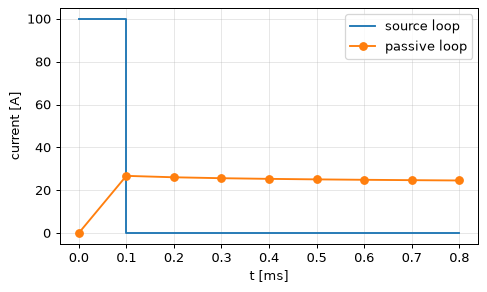

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.step(rows[:, 0] * 1e3, rows[:, 1], where="post", label="source loop")
ax.plot(rows[:, 0] * 1e3, rows[:, 2], "o-", label="passive loop")
ax.set_xlabel("t [ms]"); ax.set_ylabel("current [A]"); ax.grid(alpha=0.3); ax.legend(); plt.show()

## The whole system, mirrored

The quarter model is reflected about x = 0 and y = 0 for the picture (the current of the reflected copies follows from
the symmetry). Shown right after the switch-off, read back from the output file: the induced current in the passive
loop (arrows: its direction, which keeps the flux of the switched-off source), the source loop in grey, and |B| on the
plane z = 0 between the two loops.

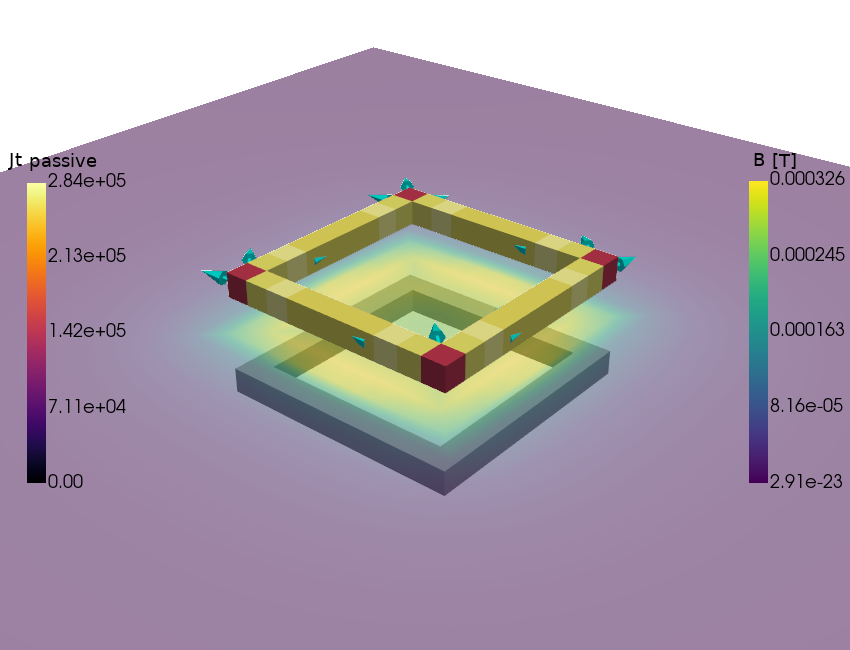

In [6]:
from pytec3d import Model
out = Model.read_model(sorted(Path("output").glob("3D_loop_cond_base_out_*.vtu"))[0], reset_arrays=False).mesh
grid = pv.wrap(out).copy()
grid.cell_data["|Jt|"] = np.linalg.norm(grid.cell_data["Jt"], axis=1)
grid.point_data["|B|"] = np.linalg.norm(grid.point_data["B"], axis=1)
quarter = [grid]
quarter.append(grid.reflect((1, 0, 0), point=(0, 0, 0)))
quarter += [q.reflect((0, 1, 0), point=(0, 0, 0)) for q in list(quarter)]

pl = pv.Plotter(window_size=(850, 650))
limit = max(q.threshold(value=(24, 24), scalars="TYPE")["|Jt|"].max() for q in quarter)
for q in quarter:
    passive = q.threshold(value=(24, 24), scalars="TYPE")
    pl.add_mesh(q.threshold(value=(23, 23), scalars="TYPE"), color="lightgray")
    pl.add_mesh(passive, scalars="|Jt|", cmap="inferno", clim=[0, limit], show_scalar_bar=q is grid,
                scalar_bar_args={"title": "|Jt| passive", "vertical": True, "position_x": 0.03, "position_y": 0.25, "height": 0.5, "width": 0.06})
    pl.add_mesh(passive.cell_centers().glyph(orient="Jt", scale=False, factor=0.03), color="cyan")
    pl.add_mesh(q.slice(normal="z", origin=(0, 0, 0)), scalars="|B|", cmap="viridis", opacity=0.5,
                show_scalar_bar=q is grid, scalar_bar_args={"title": "|B| [T]", "vertical": True, "position_x": 0.88, "position_y": 0.25, "height": 0.5, "width": 0.06})
pl.camera_position = [(0.25, -0.3, 0.22), (0, 0, 0), (0, 0, 1)]
pl.show()
with quietly():
    solver.close()